c:\Users\Sukanya\Downloads\netflix project
['1.png', '10.png', '2.png', '3.png', '4.png', '5.png', '6.png', '7.png', '8.png', '9.png', 'netflix.ipynb']
             id                                title   type  \
0      ts300399  Five Came Back: The Reference Films   SHOW   
1       tm82169                                Rocky  MOVIE   
2       tm17823                               Grease  MOVIE   
3      tm191099                            The Sting  MOVIE   
4       tm69975                             Rocky II  MOVIE   
...         ...                                  ...    ...   
6132  tm1303784             Ø¹Ø¨ÙˆØ¯ ÙÙŠ Ø§Ù„Ø¨ÙŠØª  MOVIE   
6133  tm1260999                              Sweetie  MOVIE   
6134  tm1310286            Sommore: Queen Chandelier  MOVIE   
6135  tm1072700                         All Na Vibes  MOVIE   
6136   tm561709                      Going to Heaven  MOVIE   

                                            description  release_year  \
0     This collect

C:\Users\Sukanya\AppData\Local\Temp\ipykernel_27096\3532524104.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = 'type', data = df, palette = 'coolwarm')


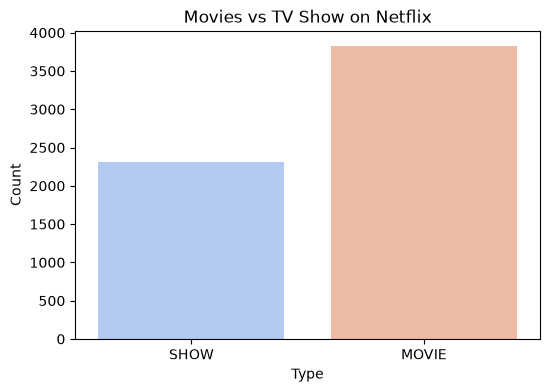

['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from zipfile import ZipFile
import os

print(os.getcwd())
print(os.listdir())


#import dataset
df = pd.read_excel(r"C:\Users\Sukanya\OneDrive\Documents\netflix_titles.csv.xlsx")
print(df)

#explore data
df.info()    # Structure of the DataFrame
df.head()    # Shows first 5 rows
df.tail()    # Shows last 5 rows
df.dtypes    # Data types of each column
df.isnull().sum()  #total missing values in entire dataset

#analyze dataset
# 1.Count the number of Movies and TV Shows
type_counts = df['type'].value_counts()
print("Movies vs TV Shows:")
print(type_counts)

# visualize it in bar chart.
plt.figure(figsize=(6,4))
sns.countplot(x = 'type', data = df, palette = 'coolwarm')
plt.title("Movies vs TV Show on Netflix")
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()



print(df.columns.tolist())




Top 10 Genres on Netflix:
genres
['drama'      1337
['comedy'      895
'drama'        828
'comedy'       613
'drama']       593
'romance']     568
['comedy']     516
'action'       516
'thriller'     465
'comedy']      461
Name: count, dtype: int64


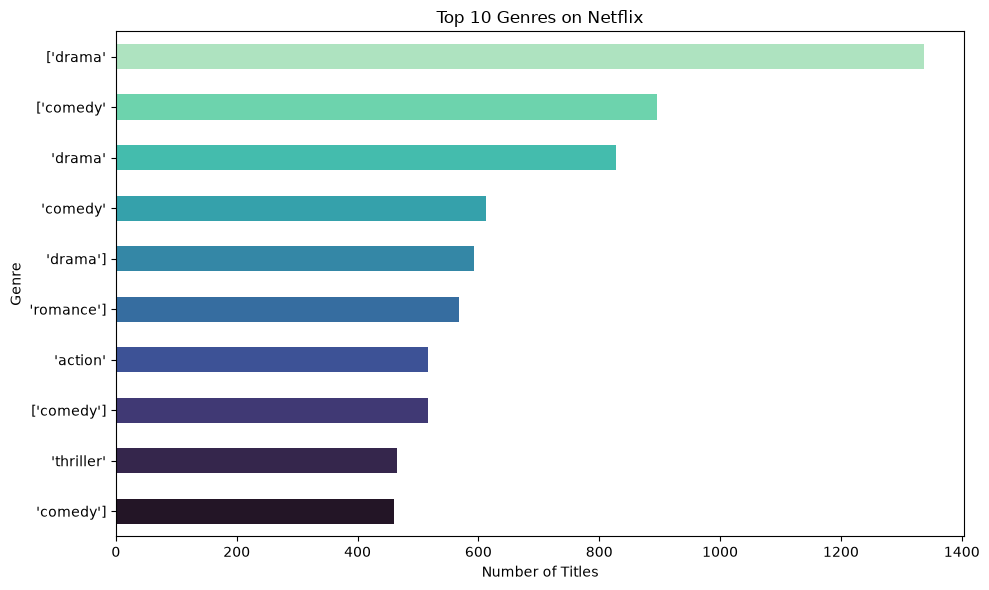

In [29]:




df.columns = df.columns.astype(str).str.strip()

# Find the genre column
possible_columns = ["listed_in", "genres", "Genre", "genre"]

genre_column = next(
    (col for col in possible_columns if col in df.columns),
    None
)

if genre_column is None:
    print("Genre column not found.")
    print("Available columns:", df.columns.tolist())

else:
    # Count individual genres
    genres = df[genre_column].dropna().astype(str)

    top_genres = (
        genres.str.split(",")
        .explode()
        .str.strip()
        .replace("", pd.NA)
        .dropna()
        .value_counts()
        .head(10)
    )

    print("Top 10 Genres on Netflix:")
    print(top_genres)

    # Visualize
    plt.figure(figsize=(10, 6))
    top_genres.sort_values().plot(
        kind="barh",
        color=sns.color_palette(
        "mako", n_colors=len(top_genres)
    ))

    plt.title("Top 10 Genres on Netflix")
    plt.xlabel("Number of Titles")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()


['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
Top 10 Countries Producing Netflix Content:
production_countries
['US']    1981
['IN']     633
['JP']     278
['KR']     259
['GB']     235
['ES']     177
[]         176
'US']      165
['US'      145
['FR']     121
Name: count, dtype: int64


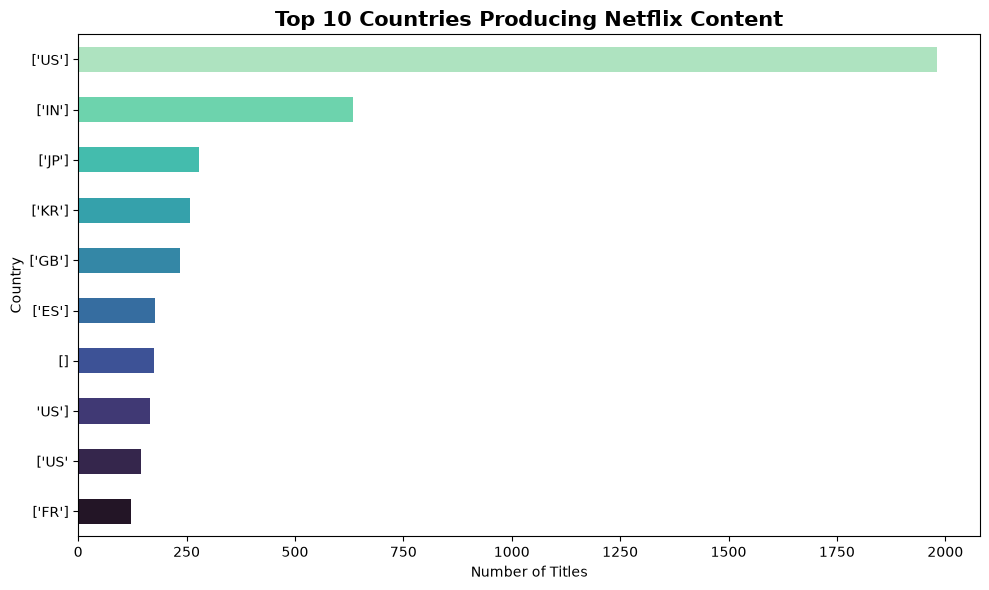

In [26]:

# Top 10 Countries Producing Netflix Content

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Check for the country column
print(df.columns.tolist())

# Remove missing country values
countries = df["production_countries"].dropna()

# Split multiple countries and count each country
top_countries = (
    countries.astype(str)
    .str.split(",")
    .explode()
    .str.strip()
    .replace("", pd.NA)
    .dropna()
    .value_counts()
    .head(10)
)

# Display results
print("Top 10 Countries Producing Netflix Content:")
print(top_countries)

# Rainbow color bar chart
plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(
    kind="barh",
    color=sns.color_palette(
        "mako", n_colors=len(top_genres)
    )
)

plt.title(
    "Top 10 Countries Producing Netflix Content",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


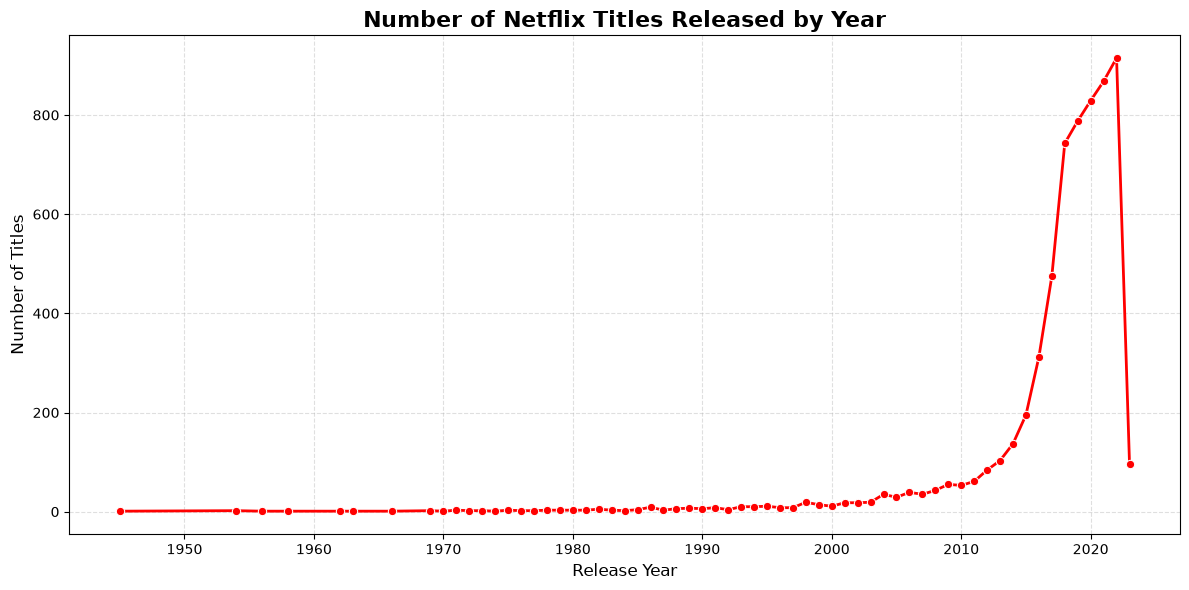

In [21]:

# Number of Netflix Titles Released by Year

# Convert release_year to numeric
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Count titles released each year
year_counts = (
    df["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

# Create line plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    color="red",
    linewidth=2,
    marker="o"
)

plt.title(
    "Number of Netflix Titles Released by Year",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


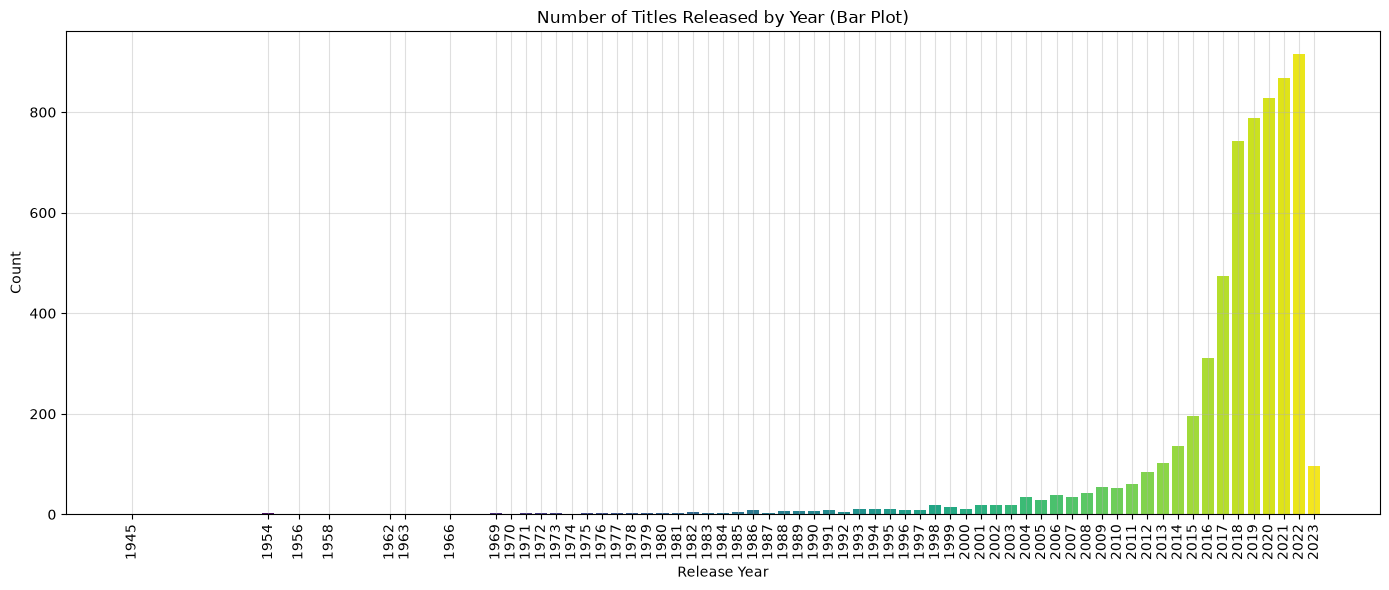

In [25]:

# Number of Titles Released by Year

year_counts = (
    df["release_year"]
    .dropna()
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 6))

# Green-to-yellow gradient matching your screenshot
colors = sns.color_palette(
    "viridis", n_colors=len(year_counts)
)

plt.bar(
    year_counts.index,
    year_counts.values,
    color=colors,
    width=0.8
)

plt.title("Number of Titles Released by Year (Bar Plot)")
plt.xlabel("Release Year")
plt.ylabel("Count")

plt.xticks(year_counts.index, rotation=90)
plt.grid(axis="both", alpha=0.4)

plt.tight_layout()
plt.show()
